# Heart Disease – Exploratory Data Analysis

## 1. Introducción

Este proyecto desarrolla un análisis exploratorio de datos (EDA) utilizando el dataset Heart Disease – Cleveland, obtenido del repositorio UCI Machine Learning Repository.

El objetivo es analizar la distribución de variables clínicas y demográficas, caracterizar sus propiedades estadísticas e identificar valores atípicos mediante el método del rango intercuartílico (IQR).

Se prestará especial atención a las variables numéricas relacionadas con la salud cardiovascular, evaluando sus distribuciones y posibles valores extremos.

## Objetivos

- Explorar las variables categóricas y numéricas del dataset.
- Analizar las distribuciones mediante visualizaciones.
- Calcular medidas de tendencia central, dispersión, asimetría y curtosis.
- Identificar y segmentar valores atípicos utilizando IQR.
- Interpretar los resultados y evaluar posibles estrategias de tratamiento.

**Fuente:** UCI Machine Learning Repository – Heart Disease (Cleveland).

In [2]:
# Importación de librerías para el análisis de datos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de visualizaciones
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Configuración para mostrar todas las columnas
pd.set_option("display.max_columns", None)

In [3]:
from pathlib import Path

# Definir la ruta raíz del proyecto
PROJECT_ROOT = Path.cwd().parent

# Definir la ruta del archivo de datos
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data"

# Verificar que el archivo exista
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {DATA_PATH}")

# Nombres originales de las variables
column_names = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

# Cargar el dataset
df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=column_names,
    na_values="?"
)

# Mostrar los primeros registros
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
# Dimensiones del dataset
print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de variables: {df.shape[1]}")

# Información general del dataset
df.info()

Cantidad de registros: 303
Cantidad de variables: 14
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [5]:
# Cantidad y porcentaje de valores faltantes por variable
missing_data = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().sum() / len(df)) * 100
})

missing_data[missing_data["Missing values"] > 0]

,Missing values,Percentage (%)
ca,4,1.320132
thal,2,0.660066


In [6]:
# Cantidad de registros duplicados
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


In [7]:
# Cantidad de valores únicos por variable
for column in df.columns:
    print(f"{column}: {df[column].nunique()} valores únicos")

age: 41 valores únicos
sex: 2 valores únicos
cp: 4 valores únicos
trestbps: 50 valores únicos
chol: 152 valores únicos
fbs: 2 valores únicos
restecg: 3 valores únicos
thalach: 91 valores únicos
exang: 2 valores únicos
oldpeak: 40 valores únicos
slope: 3 valores únicos
ca: 4 valores únicos
thal: 3 valores únicos
num: 5 valores únicos


In [8]:
# Resumen estadístico de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [9]:
# Crear etiquetas descriptivas para las variables categóricas

df["sex_label"] = df["sex"].map({
    0: "Female",
    1: "Male"
})

df["cp_label"] = df["cp"].map({
    1: "Typical angina",
    2: "Atypical angina",
    3: "Non-anginal pain",
    4: "Asymptomatic"
})

# Agrupar la variable objetivo en presencia o ausencia de enfermedad
df["disease_status"] = np.where(
    df["num"] == 0,
    "No disease",
    "Disease present"
)

# Verificar las nuevas variables
df[["sex", "sex_label", "cp", "cp_label", "num", "disease_status"]].head()

,sex,sex_label,cp,cp_label,num,disease_status
0,1.0,Male,1.0,Typical angina,0,No disease
1,1.0,Male,4.0,Asymptomatic,2,Disease present
2,1.0,Male,4.0,Asymptomatic,1,Disease present
3,1.0,Male,3.0,Non-anginal pain,0,No disease
4,0.0,Female,2.0,Atypical angina,0,No disease


## 2. Preparación y calidad de los datos

El dataset contiene 303 registros y 14 variables originales. 
No se identificaron registros duplicados.

Se encontraron 6 valores faltantes:
- 4 en la variable `ca`.
- 2 en la variable `thal`.

Debido a su baja proporción y a que estas variables no forman parte
del análisis principal de outliers, se decidió conservar los valores
faltantes sin realizar imputaciones ni eliminar registros.

También se identificaron variables categóricas codificadas
numéricamente. Para facilitar su interpretación en las visualizaciones,
se crearon etiquetas descriptivas sin modificar los datos originales.

La variable `num` se utilizó para construir una clasificación binaria
de presencia o ausencia de enfermedad cardíaca.

## 3. Distribución de variables categóricas

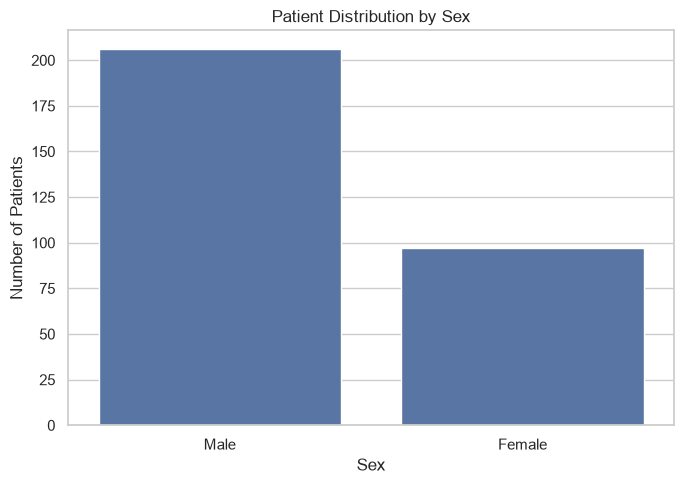

In [10]:
# Frecuencia de pacientes según sexo
sex_counts = df["sex_label"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=sex_counts.index,
    y=sex_counts.values
)

plt.title("Patient Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

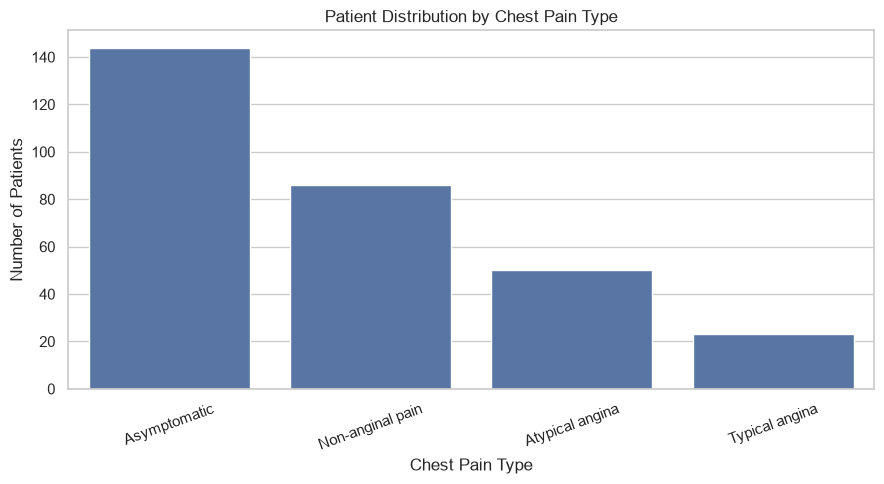

In [11]:
# Frecuencia según tipo de dolor torácico
cp_counts = df["cp_label"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=cp_counts.index,
    y=cp_counts.values
)

plt.title("Patient Distribution by Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

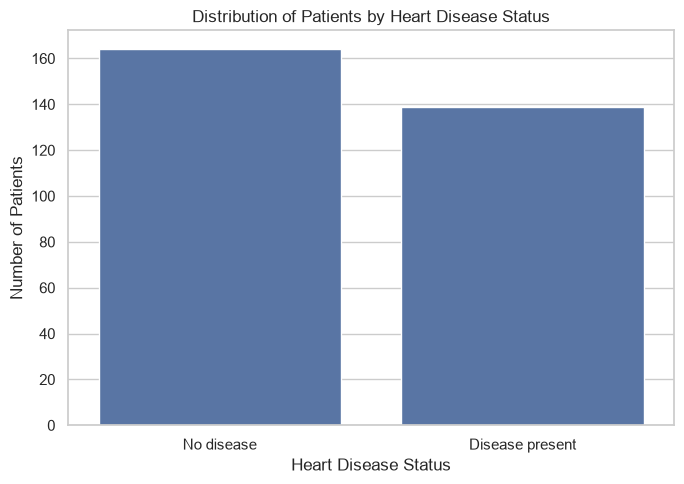

In [12]:
# Frecuencia según presencia o ausencia de enfermedad
disease_counts = df["disease_status"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=disease_counts.index,
    y=disease_counts.values
)

plt.title("Distribution of Patients by Heart Disease Status")
plt.xlabel("Heart Disease Status")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

### Interpretación de las variables categóricas

**Distribución por sexo**

La muestra presenta una mayor proporción de pacientes masculinos, aproximadamente el doble que de pacientes femeninos. Esto evidencia un desequilibrio en la composición de la muestra según sexo.

**Distribución por tipo de dolor torácico**

La categoría más frecuente es "Asymptomatic", seguida de "Non-anginal pain". Las categorías correspondientes a los distintos tipos de angina presentan frecuencias menores.

**Distribución según presencia de enfermedad cardíaca**

La cantidad de pacientes sin enfermedad cardíaca es ligeramente superior a la de pacientes con diagnóstico positivo. Sin embargo, ambas categorías presentan frecuencias relativamente similares, por lo que no existe un desequilibrio marcado en esta clasificación binaria.

## 4. Distribución de variables numéricas

In [13]:
# Seleccionar variables numéricas para el análisis
numerical_vars = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Calcular estadísticos descriptivos
numerical_stats = df[numerical_vars].describe().T

numerical_stats

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [14]:
# Calcular asimetría y curtosis
distribution_stats = pd.DataFrame({
    "Skewness": df[numerical_vars].skew(),
    "Kurtosis": df[numerical_vars].kurtosis()
})

distribution_stats

,Skewness,Kurtosis
age,-0.209060,-0.523383
trestbps,0.706035,0.880074
chol,1.135503,4.491724
thalach,-0.537449,-0.053541
oldpeak,1.269720,1.575813


### Interpretación de las distribuciones numéricas

El análisis de asimetría y curtosis permite identificar diferencias en la forma de distribución de las variables estudiadas.

La variable `age` presenta una distribución relativamente simétrica, mientras que `thalach` muestra una leve asimetría negativa.

Por otro lado, `trestbps`, `chol` y `oldpeak` presentan asimetría positiva, especialmente `chol` y `oldpeak`. Esto indica la presencia de valores elevados que generan una cola hacia la derecha de sus distribuciones.

En cuanto a la curtosis, `chol` presenta el valor más elevado, seguido de `oldpeak`. Esto sugiere distribuciones con colas más pesadas que una distribución normal, por lo que resulta interesante examinar estas variables en busca de posibles valores atípicos.

Estos resultados se utilizarán como referencia para el análisis visual y la posterior identificación de outliers.

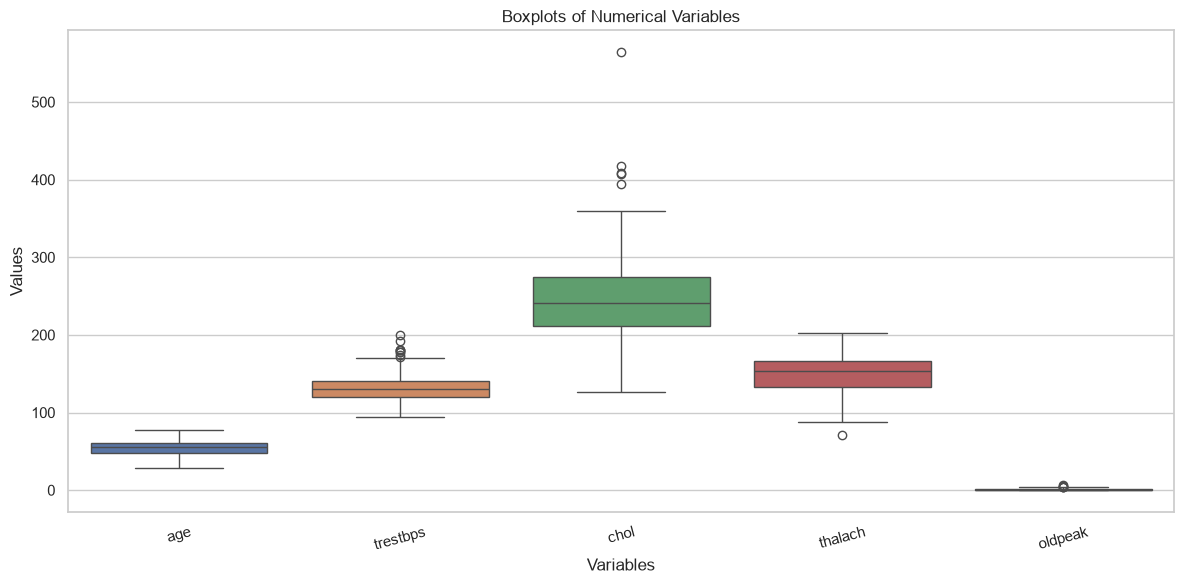

In [15]:
# Visualizar la distribución de las variables numéricas mediante boxplots

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_vars])

plt.title("Boxplots of Numerical Variables")
plt.xlabel("Variables")
plt.ylabel("Values")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

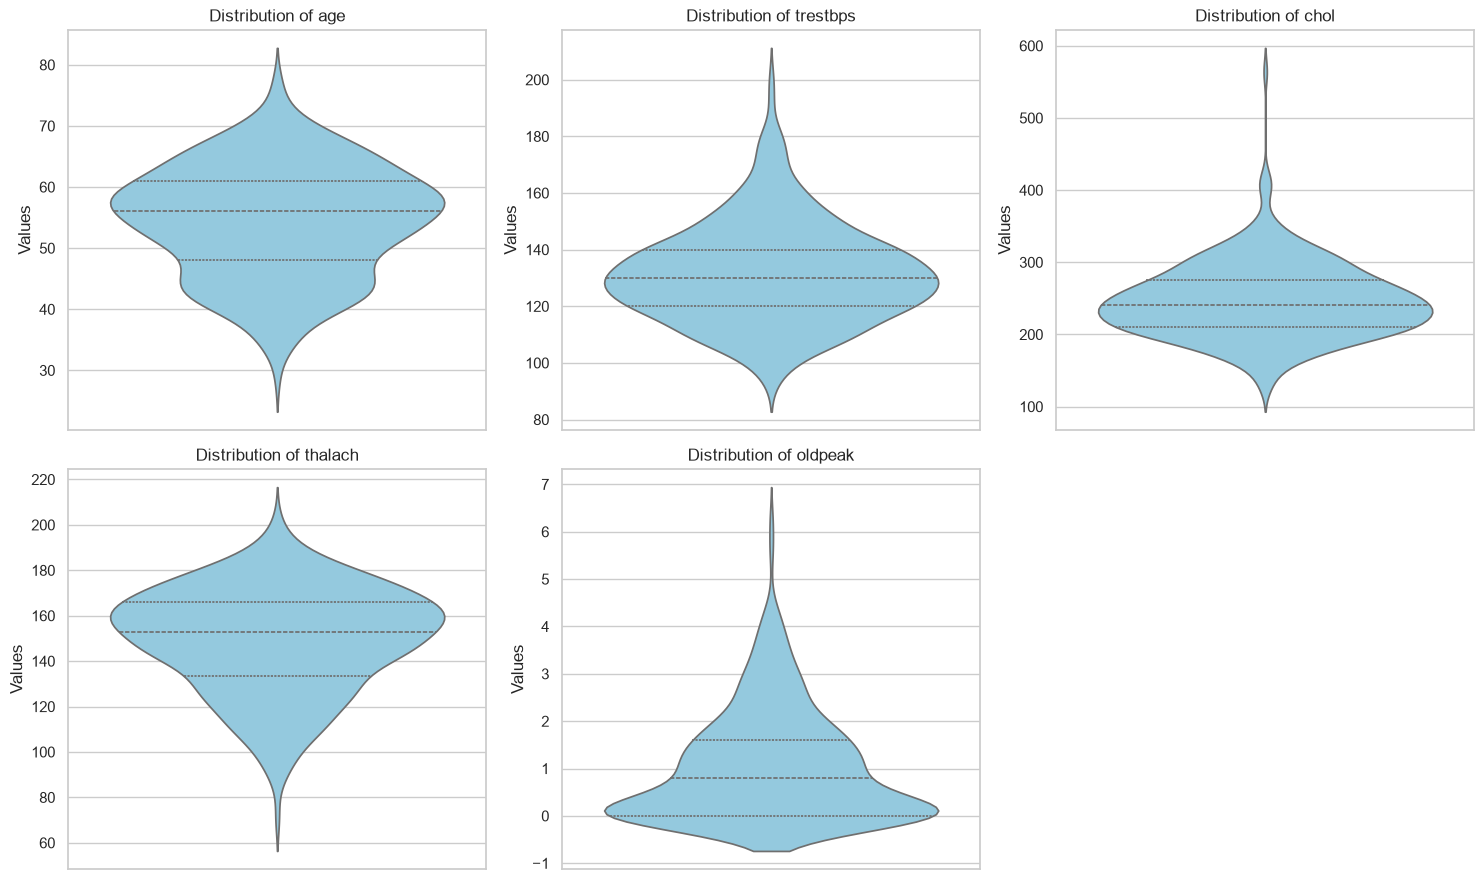

In [16]:
# Visualizar la distribución de cada variable mediante violin plots

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, variable in enumerate(numerical_vars):
    sns.violinplot(
        y=df[variable],
        ax=axes[i],
        inner="quartile",
        color="skyblue"
    )

    axes[i].set_title(f"Distribution of {variable}")
    axes[i].set_ylabel("Values")

# Eliminar el sexto espacio vacío
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

### Interpretación de violin plots

Los violin plots permiten observar la forma y concentración de las distribuciones de las variables numéricas.

Se identifican diferencias importantes entre ellas. Las variables `age` y `thalach` presentan distribuciones relativamente concentradas, mientras que `trestbps`, `chol` y `oldpeak` muestran colas hacia valores superiores o inferiores.

En particular, `chol` y `oldpeak` presentan una concentración de observaciones en valores relativamente bajos o intermedios y una extensión hacia valores elevados. Este comportamiento coincide con los resultados de asimetría y curtosis calculados previamente.

En conjunto, las visualizaciones permiten identificar posibles valores extremos y justifican la aplicación de un método estadístico para detectarlos y cuantificarlos.

In [17]:
# Identificar outliers mediante el método IQR

outlier_results = []

for variable in numerical_vars:

    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[variable] < lower_limit) |
        (df[variable] > upper_limit)
    ]

    outlier_results.append({
        "Variable": variable,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower limit": lower_limit,
        "Upper limit": upper_limit,
        "Outliers count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Variable,Q1,Q3,IQR,Lower limit,Upper limit,Outliers count
0,age,48.0,61.0,13.0,28.50,80.50,0
1,trestbps,120.0,140.0,20.0,90.00,170.00,9
2,chol,211.0,275.0,64.0,115.00,371.00,5
3,thalach,133.5,166.0,32.5,84.75,214.75,1
4,oldpeak,0.0,1.6,1.6,-2.40,4.00,5


### Resultados de la detección de outliers mediante IQR

Se aplicó el método del rango intercuartílico (IQR) a las cinco variables numéricas seleccionadas.

Los resultados muestran que `age` no presenta valores atípicos según este criterio. En cambio, `trestbps` presenta 9 valores extremos, `chol` presenta 5, `thalach` presenta 1 y `oldpeak` presenta 5.

Las variables `chol` y `oldpeak` muestran valores superiores a sus respectivos límites máximos, mientras que `thalach` presenta un valor inferior a su límite mínimo.

Estos resultados coinciden con los patrones observados en los boxplots y violin plots.

La detección estadística no implica que los valores identificados sean errores. Por tratarse de datos clínicos, se conservarán inicialmente para evitar eliminar observaciones potencialmente válidas. Su tratamiento deberá considerar el contexto de cada variable y el objetivo del análisis.

In [18]:
# Obtener el detalle de los outliers identificados

outlier_details = []

for variable in numerical_vars:

    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    mask = (
        (df[variable] < lower_limit) |
        (df[variable] > upper_limit)
    )

    for index, value in df.loc[mask, variable].items():
        outlier_details.append({
            "Record": index + 1,
            "Variable": variable,
            "Value": value
        })

outlier_details_df = pd.DataFrame(outlier_details)

outlier_details_df

,Record,Variable,Value
0,15,trestbps,172.0
1,84,trestbps,180.0
2,127,trestbps,200.0
3,173,trestbps,174.0
4,184,trestbps,178.0
5,189,trestbps,192.0
6,202,trestbps,180.0
7,214,trestbps,178.0
8,232,trestbps,180.0
9,49,chol,417.0


In [19]:
# Obtener los registros únicos que presentan al menos un outlier

outlier_record_indices = sorted(
    outlier_details_df["Record"].unique() - 1
)

# Examinar sus características clínicas
outlier_records = df.loc[
    outlier_record_indices,
    [
        "age",
        "sex_label",
        "trestbps",
        "chol",
        "thalach",
        "oldpeak",
        "disease_status",
        "num"
    ]
]

outlier_records

,age,sex_label,trestbps,chol,thalach,oldpeak,disease_status,num
14,52.0,Male,172.0,199.0,162.0,0.5,No disease,0
48,65.0,Female,140.0,417.0,157.0,0.8,No disease,0
83,68.0,Male,180.0,274.0,150.0,1.6,Disease present,3
91,62.0,Female,160.0,164.0,145.0,6.2,Disease present,3
121,63.0,Female,150.0,407.0,154.0,4.0,Disease present,4
123,55.0,Male,140.0,217.0,111.0,5.6,Disease present,3
126,56.0,Female,200.0,288.0,133.0,4.0,Disease present,3
152,67.0,Female,115.0,564.0,160.0,1.6,No disease,0
172,59.0,Female,174.0,249.0,143.0,0.0,Disease present,1
173,62.0,Female,140.0,394.0,157.0,1.2,No disease,0


### Análisis y tratamiento de los valores atípicos

Luego de aplicar el método IQR, se identificaron 20 detecciones de valores atípicos distribuidas entre cuatro variables numéricas: `trestbps`, `chol`, `thalach` y `oldpeak`.

Estas detecciones corresponden a 19 registros diferentes, ya que uno de ellos presenta valores extremos en dos variables simultáneamente.

La variable `age` no presentó valores atípicos según este criterio.

Al examinar los registros identificados, se observó que los valores extremos aparecen tanto en pacientes con diagnóstico positivo como negativo de enfermedad cardíaca.

Se decidió conservar todos los registros, sin aplicar eliminación ni transformación de outliers. Esta decisión se debe a que los datos corresponden a observaciones clínicas reales y no se dispone de evidencia suficiente para considerar que los valores identificados sean errores de registro.

Por lo tanto, los outliers se mantienen documentados como parte de la variabilidad presente en el conjunto de datos.

### Conclusión del análisis numérico

El análisis estadístico y visual permitió identificar diferencias en la distribución de las variables numéricas. En particular, `chol` y `oldpeak` presentaron mayor asimetría positiva y valores extremos superiores.

La combinación de estadísticos descriptivos, skewness, kurtosis, boxplots, violin plots y el método IQR permitió caracterizar las distribuciones e identificar posibles valores atípicos de manera sistemática.

Los resultados muestran la importancia de complementar las técnicas estadísticas con el contexto de los datos antes de decidir el tratamiento de las observaciones extremas.